In [1]:
%load_ext autoreload
%autoreload 2
import sys; sys.path.append("..")
from src.gradient_descent import batch_gradient_descent, gd_path
from src.visualization import plot_gd_path
from src.models import normal_equation

In [2]:
import numpy as np 

np.random.seed(42)

X = 2 * np.random.rand(100, 1)
y = 4 + 3 * X + np.random.randn(100, 1)

X_b = np.c_[np.ones((100, 1)), X]

In [3]:
theta_normal = normal_equation(X, y)

print("Normal Equation:")
print(theta_normal)

Normal Equation:
[[4.21509616]
 [2.77011339]]


In [4]:
np.random.seed(42)
theta_init = np.random.randn(2, 1)

theta, cost_history = batch_gradient_descent(
    X_b,
    y,
    eta=0.1,
    n_iterations=1000,
    theta_init=theta_init
)

print("GD theta: ")
print(theta)

print("\nMatches Normal Equation:")
print(np.allclose(theta, theta_normal))

GD theta: 
[[4.21509616]
 [2.77011339]]

Matches Normal Equation:
True


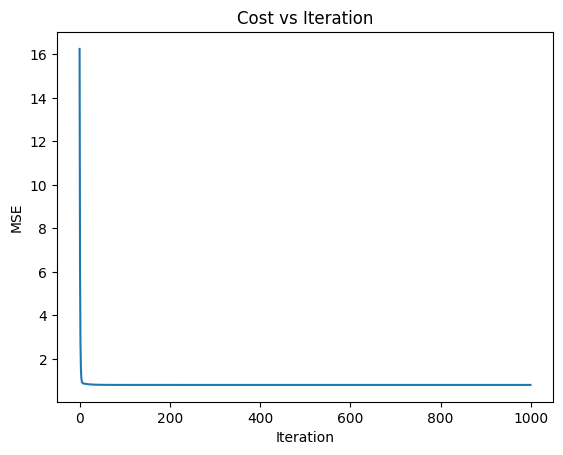

In [5]:
import matplotlib.pyplot as plt

plt.plot(cost_history)
plt.xlabel("Iteration")
plt.ylabel("MSE")
plt.title("Cost vs Iteration")
plt.show()

## Learning-Rate Experiment — Prediction

I will compare three learning rates: **eta = 0.001, 0.1, and 0.5**.

- **eta = 0.001 — Too slow:**  
  I expect Gradient Descent to make very small updates to `θ`. The fitted line should move toward the optimal solution, but only slowly over the first 10 iterations.

- **eta = 0.1 — About right:**  
  I expect Gradient Descent to make reasonably sized updates and move toward the optimal parameters efficiently. The fitted line should approach the underlying relationship in the data.

- **eta = 0.5 — Likely to fail/diverge:**  
  I expect the learning rate to be too large, causing Gradient Descent to take very large steps and overshoot the minimum repeatedly. The fitted line may oscillate or diverge instead of converging.

### Prediction

- eta = 0.001: too slow
- eta = 0.1: good / converges
- eta = 0.5: too large / diverges

The reason is that the learning rate controls the size of each update:

- small eta: small steps
- good eta: controlled steps toward the minimum
- large eta: overshooting the minimum


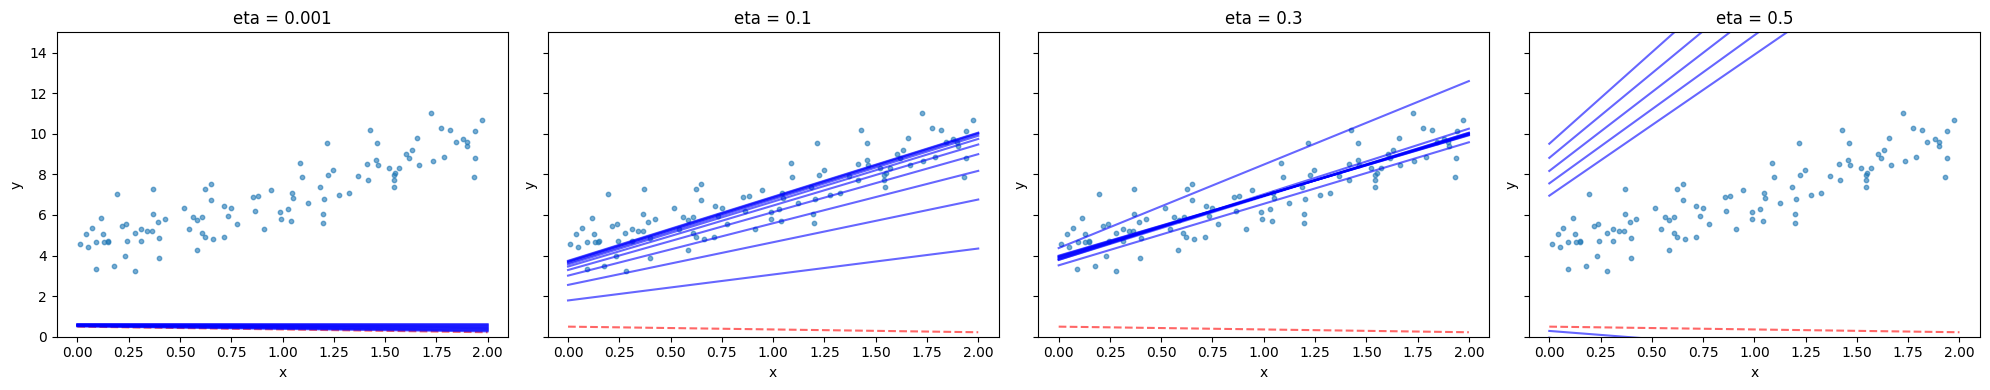

In [6]:
plot_gd_path(
    X,
    y,
    X_b,
    gd_path,
    etas=[0.001, 0.1, 0.3, 0.5],
    theta_init=theta_init,
    n_iterations=10
)

In [7]:
# Cost evidence

def mse_of(theta):
    return float(np.mean((X_b @ theta - y) ** 2))

for eta in [0.001, 0.1, 0.5]:
    path = gd_path(X_b, y, eta, n_iterations=10, theta_init=theta_init)
    print(f"eta = {eta}")
    print([round(mse_of(t), 2) for t in path])
    print()


eta = 0.001
[45.42, 45.05, 44.69, 44.32, 43.97, 43.61, 43.26, 42.91, 42.57, 42.22, 41.88]

eta = 0.1
[45.42, 16.25, 6.2, 2.73, 1.53, 1.11, 0.96, 0.91, 0.89, 0.88, 0.87]

eta = 0.5
[45.42, 51.35, 58.1, 65.77, 74.47, 84.35, 95.56, 108.28, 122.7, 139.07, 157.63]



## Learning Rate Experiment — Observations

### η = 0.001 — Too Slow 

- The blue lines barely move **away from the red dashed starting line** during the first 10 iterations. The cost decreases slowly, and the parameters are still far from the optimum after 10 iterations.

- The cost history confirms this:

```text
[45.42, 45.05, 44.69, 44.32, 43.97, 43.61, 43.26, 42.91, 42.57, 42.22, 41.88]
```

- The cost decreases from **45.42 to 41.88** after 10 iterations, which is a relatively small improvement.

- Since η = 0.1 took **365 iterations** to reach **tol = 1e-6**, a learning rate 100× smaller (η = 0.001) would require roughly **36,500 iterations** as a rough estimate.

- Therefore, **η = 0.001 is too slow.**

### η = 0.1 — Good Learning Rate 

- The blue lines quickly move **away from the red dashed starting line and onto the data cloud**. They approach the solution smoothly rather than repeatedly crossing from one side of the data cloud to the other.

- The steepest-direction projection from the cell above confirms the one-sided approach: it stays negative and shrinks, `-4.64 -> -2.72 -> -1.60 -> -0.94 -> ...`.

- The cost history confirms this:

```text
[45.42, 16.25, 6.20, 2.73, 1.53, 1.11, 0.96, 0.91, 0.89, 0.88, 0.87]
```

- The cost drops rapidly from **45.42 to 0.87** in only 10 iterations and then begins to flatten.

- For my data, **η = 0.1** reached **tol = 1e-6** after **365 iterations**, making it a reasonable learning rate.

- Therefore, **η = 0.1 converges successfully and efficiently.**

### η = 0.5 — Diverges 

- The Gradient Descent update is `theta = theta - eta * gradient`.


- With **η = 0.5**, the update **η * gradient** becomes too large. Instead of taking controlled steps toward the minimum, Gradient Descent overshoots the minimum and lands on the other side.

- The next gradient points back toward the minimum, but the next update overshoots again. The error therefore grows instead of shrinking, causing the parameters to move farther and farther away from the optimum.

- My cost history shows this clearly:

```text
[45.42, 51.35, 58.10, 65.77, 74.47, 84.35, 95.56, 108.28, 122.70, 139.07, 157.63]
```

- The cost increases every iteration rather than decreasing, and the increments themselves grow.

- Projected onto the steepest direction, the error **flips sign every step and grows by about 6.5% per step**: `-4.64 -> 4.94 -> -5.26 -> 5.61 -> -5.97 ...`. That matches the multiplier `1 - 0.5 * 4.130 = -1.065` computed below.

- Therefore, **η = 0.5 is too large and causes Gradient Descent to diverge.**

### Predictions vs Results

| Learning rate | Prediction | Result |
|---|---|---|
| η = 0.001 | Too slow | **RIGHT** |
| η = 0.1 | Converges | **RIGHT** |
| η = 0.5 | Diverges | **RIGHT** |

## Why does eta = 0.5 diverge?

The Batch Gradient Descent update is:

θ ← θ − η∇MSE

The convergence condition for this quadratic cost function is:

η < 2 / λ_max

where λ_max is the largest eigenvalue of:

(2/m) X_bᵀ X_b

This λ_max represents the steepest curvature direction of the cost bowl.

If η is too large, the update can overshoot the minimum so far that the error becomes larger after every step.

In [8]:
m = len(X_b)
eigvals, eigvecs = np.linalg.eigh((2 / m) * X_b.T @ X_b)   # ascending order
lam_min, lam_max = eigvals

print(f"lam_min = {lam_min:.3f}, lam_max = {lam_max:.3f}")
print(f"1/lam_max = {1/lam_max:.3f}   (eta above this: zigzag)")
print(f"2/lam_max = {2/lam_max:.3f}   (eta above this: diverges)")
print(f"lam_max / lam_min = {lam_max/lam_min:.1f}   (how elongated the bowl is)")

lam_min = 0.339, lam_max = 4.130
1/lam_max = 0.242   (eta above this: zigzag)
2/lam_max = 0.484   (eta above this: diverges)
lam_max / lam_min = 12.2   (how elongated the bowl is)


### Why 0.5 fails

- Update: `theta <- theta - eta * gradient`. Convergence needs `eta < 2 / lam_max`.
- My values: `lam_max = 4.130`, so the stability limit is `2 / lam_max = 0.484`. `eta = 0.5` is **above** it.
- Multiplier per step at 0.5: `1 - 0.5 * 4.130 = -1.065` (sign: **negative**, magnitude: **1.065**).

### Where the behavior changes

- `eta = 0.1`: multiplier = `1 - 0.1 * 4.130 = 0.587` -> approaches from **one side**.
- `eta = 0.3`: multiplier = `1 - 0.3 * 4.130 = -0.239` -> the error **changes sign each step**, so the iterates zigzag across the minimum, but the magnitude shrinks because `|-0.239| < 1`. Therefore, it still converges.

### Predictions vs results

- `eta = 0.001` (too slow): **right**
- `eta = 0.1` (converges): **right**
- `eta = 0.5` (diverges): **right**

### Easy or slow?

- `lam_max / lam_min = 12.2` (the condition number). The bowl is **elongated**: eta must stay below `2 / lam_max = 0.484` so the steep direction is stable, but the flat direction then shrinks only by `1 - eta * lam_min` per step (`0.966` at eta = 0.1). That is why about 365 iterations are needed even though the steep direction converges in a handful. A larger ratio means slower GD, and feature scaling is what shrinks it.

In [9]:
v_max = eigvecs[:, [1]]

for eta in [0.001, 0.1, 0.3, 0.5]:

    path = gd_path(
        X_b,
        y,
        eta,
        n_iterations=10,
        theta_init=theta_init
    )

    proj = [
        (v_max.T @ (t - theta_normal)).item()
        for t in path
    ]

    multiplier = 1 - eta * lam_max

    print(f"eta = {eta}")
    print(f"multiplier = {multiplier:.3f}")
    print([round(p, 2) for p in proj])
    print()

eta = 0.001
multiplier = 0.996
[-4.64, -4.62, -4.6, -4.58, -4.57, -4.55, -4.53, -4.51, -4.49, -4.47, -4.45]

eta = 0.1
multiplier = 0.587
[-4.64, -2.72, -1.6, -0.94, -0.55, -0.32, -0.19, -0.11, -0.07, -0.04, -0.02]

eta = 0.3
multiplier = -0.239
[-4.64, 1.11, -0.27, 0.06, -0.02, 0.0, -0.0, 0.0, -0.0, 0.0, -0.0]

eta = 0.5
multiplier = -1.065
[-4.64, 4.94, -5.26, 5.61, -5.97, 6.36, -6.77, 7.21, -7.68, 8.18, -8.71]



## eta = 0.3 — Zigzag but Still Converges

For η = 0.3, the multiplier in the steepest direction is:

1 − 0.3 × 4.130 = −0.239

The multiplier is negative, so the error changes sign on successive iterations. This means Gradient Descent crosses the minimum and zigzags.

However, its absolute value is less than 1, so the magnitude of the error decreases. Therefore, η = 0.3 zigzags but still converges. The projections confirm it: `-4.64 -> 1.11 -> -0.27 -> 0.06 -> -0.02 -> ...`, where each value is about −0.239 times the previous one.

In [10]:
# Gradient Descent stopping rule.
np.random.seed(42)
theta_init = np.random.randn(2, 1)

In [11]:
tolerances = [1e-3, 1e-6, 1e-9]

for tol in tolerances:
    theta, cost_history = batch_gradient_descent(
        X_b,
        y,
        eta=0.1,
        n_iterations=100_000,
        tol=tol,
        theta_init=theta_init
    )
    n_iter = len(cost_history)

    print(f"tol = {tol:.0e}")
    print(f"iterations = {n_iter}")

    gradient = (2 / len(X_b)) * X_b.T @ (X_b @ theta - y)
    grad_norm = np.linalg.norm(gradient)
    
    print(f"gradient norm = {grad_norm:.2e}")
    print(f"theta = {theta.ravel()}")
    print()

tol = 1e-03
iterations = 165
gradient norm = 9.82e-04
theta = [4.21292823 2.77202755]

tol = 1e-06
iterations = 365
gradient norm = 9.83e-07
theta = [4.21509399 2.7701153 ]

tol = 1e-09
iterations = 565
gradient norm = 9.84e-10
theta = [4.21509616 2.77011339]



In [12]:
etas = [0.01, 0.1]

for eta in etas:
    theta, cost_history = batch_gradient_descent(
        X_b,
        y,
        eta=eta,
        n_iterations=100_000,
        tol=1e-6,
        theta_init=theta_init
    )
    n_iter = len(cost_history)

    print(f"eta = {eta}")
    print(f"iterations = {n_iter}")

    gradient = (2 / len(X_b)) * X_b.T @ (X_b @ theta - y)
    grad_norm = np.linalg.norm(gradient)
    
    print(f"gradient norm = {grad_norm:.2e}")
    print(f"theta = {theta.ravel()}")
    print()

eta = 0.01
iterations = 3703
gradient norm = 9.97e-07
theta = [4.21509396 2.77011533]

eta = 0.1
iterations = 365
gradient norm = 9.83e-07
theta = [4.21509399 2.7701153 ]



## Stopping rule and eta vs iterations: observations

| tol | iterations (eta = 0.1) |
|---|---|
| 1e-3 | 165 |
| 1e-6 | 365 |
| 1e-9 | 565 |

- Each 1000x tighter tolerance costs a constant **+200 iterations**, not a multiplicative increase. The error shrinks by a fixed factor per step, so each extra digit of accuracy costs the same number of extra steps.
- eta = 0.01 needed 3703 iterations vs 365 for eta = 0.1: about **10x more**. Near the minimum, the slowest direction shrinks by `1 - eta * lam_min` per step, so a 10x smaller eta makes the per-step progress about 10x smaller.
- Tighter tolerance gives a better theta: at tol = 1e-9 it matches the Normal Equation to every printed decimal.
- The check below predicts the +200 from `lam_min` alone.

In [13]:
# Slowest direction: the error shrinks by (1 - eta * lam_min) per step.
# Steps needed for the gradient to drop 1000x = ln(1000) / -ln(multiplier)
for eta in [0.1, 0.01]:
    mult = 1 - eta * lam_min
    steps = np.log(1000) / -np.log(mult)
    print(f"eta = {eta}: slow-direction multiplier = {mult:.4f}, predicted steps per 1000x tighter tol = {steps:.0f}")

eta = 0.1: slow-direction multiplier = 0.9661, predicted steps per 1000x tighter tol = 200
eta = 0.01: slow-direction multiplier = 0.9966, predicted steps per 1000x tighter tol = 2032
